In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
df = pd.read_csv("student_scores.csv")
subjects = ["Maths", "Physics", "Chemistry", "English", "Computer_Science", "Statistics"]
X = df[subjects].to_numpy(dtype=float)
print("Dataset:", X.shape[0], "students,", X.shape[1], "subjects")

Dataset: 600 students, 6 subjects


In [13]:
print("\n===== PART A: VECTORS =====")
u = X[0]
v = X[1]
print("Student 1:", u)
print("Student 2:", v)

print("Norm-1 of u:", np.sum(np.abs(u)))
print("Norm-2 of u:", round(np.sqrt(np.sum(u ** 2)), 4))
print("Norm-1 of v:", np.sum(np.abs(v)))
print("Norm-2 of v:", round(np.sqrt(np.sum(v ** 2)), 4))

dot = np.sum(u * v)
cos_theta = dot / (np.linalg.norm(u) * np.linalg.norm(v))
angle = np.degrees(np.arccos(cos_theta))
print("Dot product:", dot)
print("Angle:", round(angle, 4), "degrees")

three_subjects = ["Maths", "Physics", "Computer_Science"]
a = df.loc[0, three_subjects].to_numpy(dtype=float)
b = df.loc[1, three_subjects].to_numpy(dtype=float)
cross = np.cross(a, b)
print("Cross product:", cross)
print("Area of parallelogram:", round(np.linalg.norm(cross), 2))
print("Cross is perpendicular to a:", np.isclose(np.dot(cross, a), 0))
print("Cross is perpendicular to b:", np.isclose(np.dot(cross, b), 0))

projection = (np.dot(u, v) / np.dot(v, v)) * v
print("Projection of u on v:", np.round(projection, 2))
print("Remaining part is perpendicular to v:", np.isclose(np.dot(u - projection, v), 0))


===== PART A: VECTORS =====
Student 1: [73. 66. 75. 68. 71. 70.]
Student 2: [59. 59. 61. 74. 52. 56.]
Norm-1 of u: 423.0
Norm-2 of u: 172.8439
Norm-1 of v: 361.0
Norm-2 of v: 148.3206
Dot product: 25420.0
Angle: 7.4482 degrees
Cross product: [-757.  393.  413.]
Area of parallelogram: 947.66
Cross is perpendicular to a: True
Cross is perpendicular to b: True
Projection of u on v: [68.17 68.17 70.49 85.51 60.09 64.71]
Remaining part is perpendicular to v: True


In [14]:
print("\n===== PART B: MATRICES =====")
A = X[0:6]
B = X[6:12]
print("A + B:\n", A + B)
print("A x B:\n", np.dot(A, B))
print("Transpose of A:\n", A.T)

det_A = np.linalg.det(A)
print("Determinant of A:", round(det_A, 2))
print("Rank of A:", np.linalg.matrix_rank(A))

if abs(det_A) > 1e-9:
    inverse_A = np.linalg.inv(A)
    print("Inverse of A:\n", np.round(inverse_A, 4))
    print("A x inverse = Identity:", np.allclose(np.dot(A, inverse_A), np.eye(6)))
else:
    print("A is singular, inverse does not exist")

gram = np.dot(X.T, X)
print("Full matrix shape:", X.shape, "-> not square, so no determinant")
print("X^T X shape:", gram.shape, "| determinant:", f"{np.linalg.det(gram):.3e}")


===== PART B: MATRICES =====
A + B:
 [[148. 136. 131. 125. 147. 148.]
 [127. 121. 131. 144. 128. 119.]
 [138. 121. 149. 158. 157. 130.]
 [138. 122. 128. 149. 153. 134.]
 [111. 103. 134. 140. 136. 111.]
 [121. 127. 124. 130. 144. 124.]]
A x B:
 [[27955. 26166. 28786. 30739. 31226. 27483.]
 [23953. 22252. 24445. 26034. 26551. 23379.]
 [31371. 29404. 32534. 34772. 35170. 30891.]
 [28774. 27056. 29921. 31530. 32047. 28349.]
 [20248. 18950. 21112. 22391. 22596. 19960.]
 [22368. 20946. 23262. 24692. 24960. 22008.]]
Transpose of A:
 [[73. 59. 80. 69. 51. 54.]
 [66. 59. 77. 64. 43. 49.]
 [75. 61. 86. 62. 49. 55.]
 [68. 74. 69. 83. 55. 62.]
 [71. 52. 86. 85. 63. 65.]
 [70. 56. 78. 72. 46. 54.]]
Determinant of A: -8391734.0
Rank of A: 6
Inverse of A:
 [[ 0.1458 -0.0086 -0.0734  0.0339  0.1674 -0.2617]
 [-0.1538  0.0736  0.1314  0.0571  0.0298 -0.1684]
 [-0.0115 -0.0038 -0.0022 -0.1046 -0.0527  0.2063]
 [-0.0116  0.0251 -0.0304 -0.0134 -0.0039  0.0542]
 [-0.0636 -0.0126  0.0358  0.0016  0.0324  

In [15]:
print("\n===== PART C: LINE, PLANE, HYPERPLANE =====")
slope, intercept = np.polyfit(X[:, 0], X[:, 1], 1)
print("Line (2D): Physics =", round(slope, 3), "* Maths +", round(intercept, 3))

design_3d = np.column_stack([X[:, 0], X[:, 1], np.ones(len(X))])
plane, _, _, _ = np.linalg.lstsq(design_3d, X[:, 4], rcond=None)
print("Plane (3D): CS =", round(plane[0], 3), "* Maths +", round(plane[1], 3), "* Physics +", round(plane[2], 3))

design_6d = np.column_stack([X[:, 0:5], np.ones(len(X))])
hyper, _, _, _ = np.linalg.lstsq(design_6d, X[:, 5], rcond=None)
print("Hyperplane (6D) weights:", np.round(hyper, 3))

print("\nDimension table:")
shapes = ["point", "line", "plane", "3D hyperplane", "4D hyperplane", "5D hyperplane"]
for k in range(1, 7):
    print(k, "subject(s) -> rank", np.linalg.matrix_rank(X[:, :k]), "-> hyperplane is a", shapes[k - 1])


===== PART C: LINE, PLANE, HYPERPLANE =====
Line (2D): Physics = 0.8 * Maths + 9.869
Plane (3D): CS = 0.485 * Maths + 0.295 * Physics + 20.092
Hyperplane (6D) weights: [ 0.391  0.26   0.127 -0.033  0.237 -1.5  ]

Dimension table:
1 subject(s) -> rank 1 -> hyperplane is a point
2 subject(s) -> rank 2 -> hyperplane is a line
3 subject(s) -> rank 3 -> hyperplane is a plane
4 subject(s) -> rank 4 -> hyperplane is a 3D hyperplane
5 subject(s) -> rank 5 -> hyperplane is a 4D hyperplane
6 subject(s) -> rank 6 -> hyperplane is a 5D hyperplane


In [17]:
print("\n===== PART D: EIGENVALUES AND EIGENVECTORS =====")

centered = X - X.mean(axis=0)
cov = np.dot(centered.T, centered) / (len(X) - 1)
print("Covariance matrix:")
print(pd.DataFrame(cov, index=subjects, columns=subjects).round(2))

eigenvalues, eigenvectors = np.linalg.eigh(cov)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
signs = np.where(eigenvectors.sum(axis=0) < 0, -1, 1)
eigenvectors = eigenvectors * signs

print("\nEigenvalues:", np.round(eigenvalues, 3))
print(pd.DataFrame(eigenvectors, index=subjects, columns=["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"]).round(3))

all_ok = True
for i in range(6):
    left = np.dot(cov, eigenvectors[:, i])
    right = eigenvalues[i] * eigenvectors[:, i]
    if not np.allclose(left, right):
        all_ok = False
print("Check C v = lambda v:", all_ok)

print("Trace of C:", round(np.trace(cov), 3), "| Sum of eigenvalues:", round(eigenvalues.sum(), 3))

percent = eigenvalues / eigenvalues.sum() * 100
cumulative = np.cumsum(percent)
for i in range(6):
    print("PC" + str(i + 1), "explains", round(percent[i], 2), "% | cumulative", round(cumulative[i], 2), "%")

scores = np.dot(centered, eigenvectors)


===== PART D: EIGENVALUES AND EIGENVECTORS =====
Covariance matrix:
                  Maths  Physics  Chemistry  English  Computer_Science  \
Maths             89.25    71.45      50.69    30.19             64.30   
Physics           71.45    97.80      51.49    32.48             63.43   
Chemistry         50.69    51.49      79.10    42.75             47.02   
English           30.19    32.48      42.75   100.58             33.58   
Computer_Science  64.30    63.43      47.02    33.58             83.80   
Statistics        74.22    73.92      53.03    30.37             66.41   

                  Statistics  
Maths                  74.22  
Physics                73.92  
Chemistry              53.03  
English                30.37  
Computer_Science       66.41  
Statistics             92.22  

Eigenvalues: [359.228  85.244  34.032  26.814  21.098  16.349]
                    PC1    PC2    PC3    PC4    PC5    PC6
Maths             0.445 -0.208 -0.096  0.045 -0.600  0.622
Physics      


Saved plot: no_function_plots.png


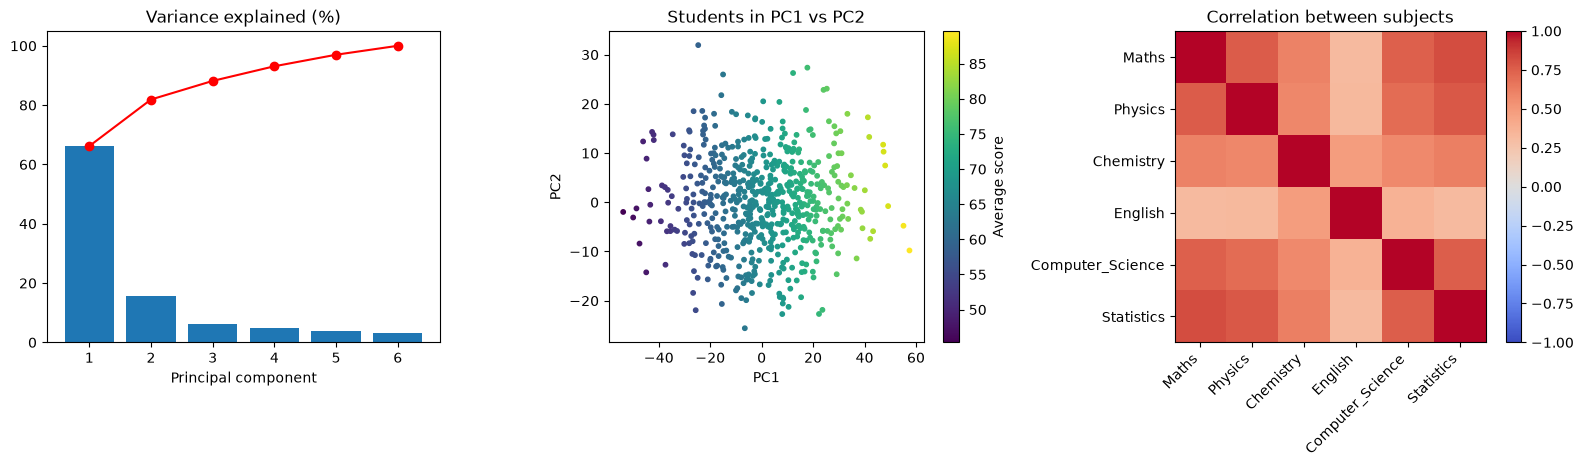

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(range(1, 7), percent)
axes[0].plot(range(1, 7), cumulative, "o-", color="red")
axes[0].set_title("Variance explained (%)")
axes[0].set_xlabel("Principal component")

plot = axes[1].scatter(scores[:, 0], scores[:, 1], c=X.mean(axis=1), s=10, cmap="viridis")
axes[1].set_title("Students in PC1 vs PC2")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
plt.colorbar(plot, ax=axes[1], label="Average score")

heat = axes[2].imshow(np.corrcoef(X.T), cmap="coolwarm", vmin=-1, vmax=1)
axes[2].set_xticks(range(6))
axes[2].set_xticklabels(subjects, rotation=45, ha="right")
axes[2].set_yticks(range(6))
axes[2].set_yticklabels(subjects)
axes[2].set_title("Correlation between subjects")
plt.colorbar(heat, ax=axes[2])

plt.tight_layout()
plt.savefig("no_function_plots.png", dpi=120)
print("\nSaved plot: no_function_plots.png")